In [1]:
print("Employee Attrition Prediction Project")

Employee Attrition Prediction Project


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

url = "https://raw.githubusercontent.com/IamVasil/IBM-HR-Analytics-Employee-Attrition-Performance/main/WA_Fn-UseC_-HR-Employee-Attrition.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nAttrition counts:")
print(df["Attrition"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())


Dataset shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Missing values:
0


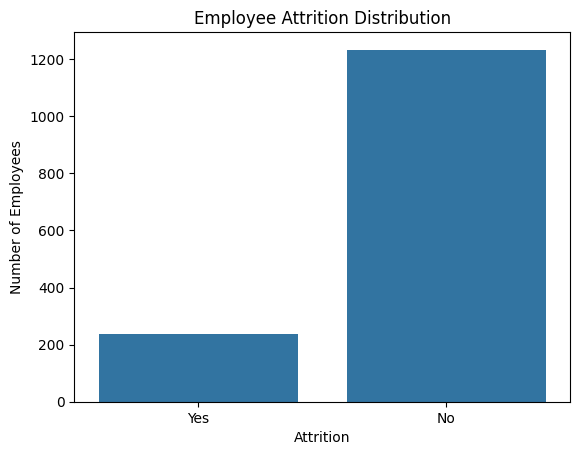

In [6]:

sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()


In [7]:

# Remove columns that have the same value for every employee
df = df.drop(
    columns=["EmployeeCount", "Over18", "StandardHours"],
    errors="ignore"
)

# Convert the target column into numbers
df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0})

# Convert text columns into numerical columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("Data preparation completed!")
print("Number of input features:", X.shape[1])
print("Number of records:", X.shape[0])
print("\nTarget values:")
print(y.value_counts())


Data preparation completed!
Number of input features: 45
Number of records: 1470

Target values:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1176
Testing records: 294


In [9]:

# Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [10]:

# Predict attrition for the test data
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 77.89 %

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.83      0.86       247
        Left       0.37      0.53      0.43        47

    accuracy                           0.78       294
   macro avg       0.64      0.68      0.65       294
weighted avg       0.82      0.78      0.79       294


Confusion Matrix:
[[204  43]
 [ 22  25]]


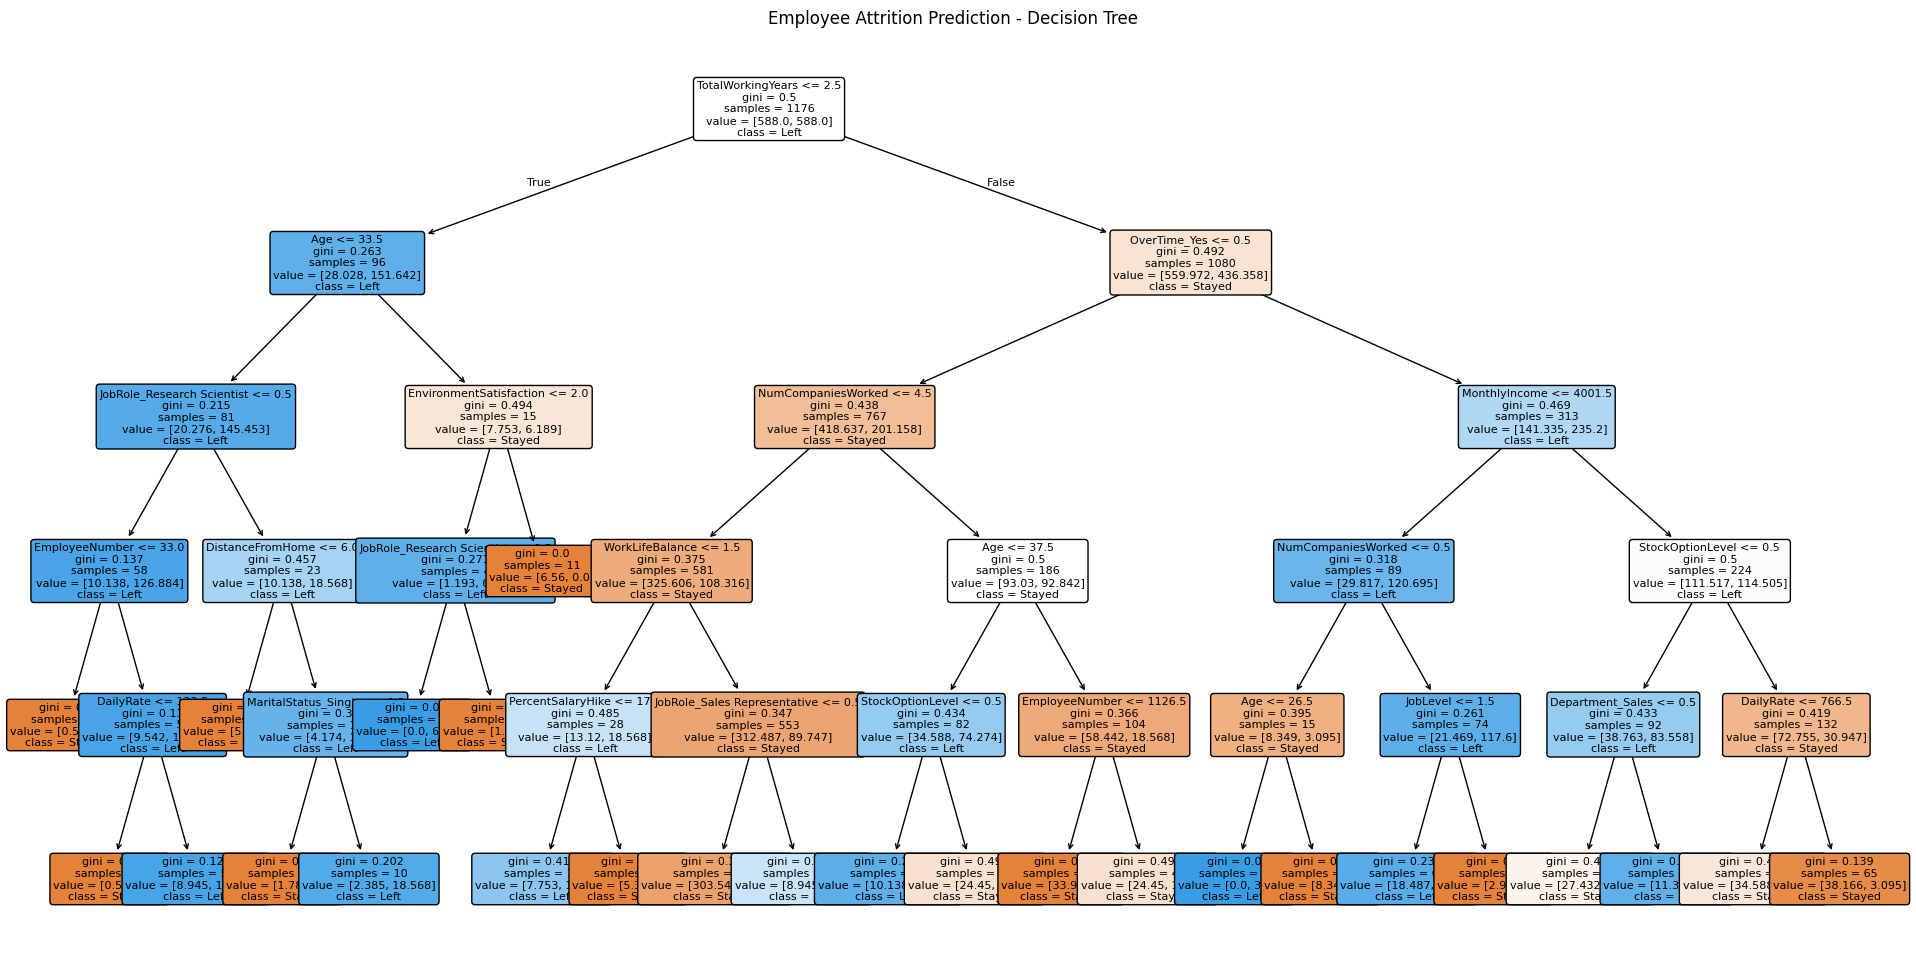

In [11]:

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Stayed", "Left"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Employee Attrition Prediction - Decision Tree")
plt.show()


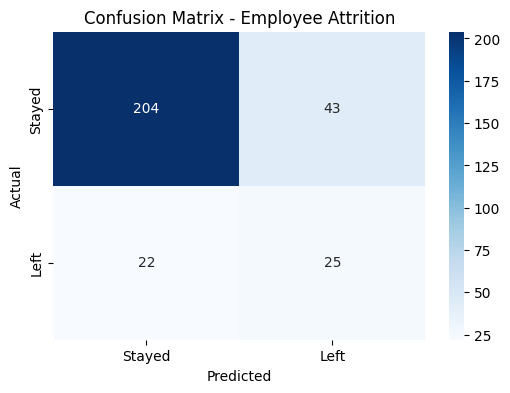

In [12]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Employee Attrition")
plt.show()


In [13]:

# Select one employee record from the test dataset
sample_employee = X_test.iloc[[0]]

# Predict attrition
prediction = model.predict(sample_employee)[0]
probabilities = model.predict_proba(sample_employee)[0]

print("Employee Attrition Prediction")

if prediction == 1:
    print("Prediction: Likely to Leave")
else:
    print("Prediction: Likely to Stay")

print("Probability of Staying:", round(probabilities[0] * 100, 2), "%")
print("Probability of Leaving:", round(probabilities[1] * 100, 2), "%")


Employee Attrition Prediction
Prediction: Likely to Leave
Probability of Staying: 6.59 %
Probability of Leaving: 93.41 %
